# ¿Qué predice ganar una medalla olímpica en atletismo?
### Modelo de regresión logística (proyecto de nota de seguimiento)

**Pregunta de negocio/investigación:** controlando por sexo, estatura, peso y tipo de prueba, ¿qué características de un atleta de **atletismo olímpico** aumentan la probabilidad de ganar medalla (oro, plata o bronce)?

**Dataset:** ["120 years of Olympic history: athletes and results"](https://github.com/rgriff23/Olympic_history) : 271,116 participaciones olímpicas individuales (Atenas 1896 – Río 2016), con edad, estatura, peso, sexo, país, deporte, evento y medalla. Es uno de los datasets deportivos más usados en la comunidad de ciencia de datos (compilado originalmente por sports-reference.com).

**Por qué atletismo:** es el deporte individual con más observaciones (38,624), con pruebas muy distintas entre sí (velocidad, resistencia, saltos, lanzamientos, marcha, combinadas), ideal para ver cómo el cuerpo "ideal" cambia según la prueba.

Este notebook sigue el mismo orden de trabajo que las guías de regresión múltiple del curso, adaptado a variable dependiente **binaria** (logit), pasando por **todas** las verificaciones de supuestos.

## 0. Revisión del dataset crudo (antes de decidir cómo limpiarlo)

Antes de aplicar cualquier filtro, se inspecciona el dataset completo para que las decisiones de la sección 1 queden respaldadas por evidencia, no solo por intuición.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score, roc_curve)
from scipy import stats as st

df = pd.read_csv('Data/athlete_events.csv')
print('Filas totales (todas las olimpiadas, todos los deportes):', df.shape[0])
df.info()


Filas totales (todas las olimpiadas, todos los deportes): 271116
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


In [2]:
print(df.columns.tolist())
print()
print('Valores faltantes por columna:')
print(df.isna().sum())


['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games', 'Year', 'Season', 'City', 'Sport', 'Event', 'Medal']

Valores faltantes por columna:
ID             0
Name           0
Sex            0
Age         9474
Height     60171
Weight     62875
Team           0
NOC            0
Games          0
Year           0
Season         0
City           0
Sport          0
Event          0
Medal     231333
dtype: int64


In [3]:
print('Numero de filas por deporte (top 10):')
print(df['Sport'].value_counts().head(10))


Numero de filas por deporte (top 10):
Sport
Athletics               38624
Gymnastics              26707
Swimming                23195
Shooting                11448
Cycling                 10859
Fencing                 10735
Rowing                  10595
Cross Country Skiing     9133
Alpine Skiing            8829
Wrestling                7154
Name: count, dtype: int64


Atletismo termina siendo el deporte individual con más observaciones de todos (38,624): más del triple que Tiro o Ciclismo, por eso se elige sobre otro deporte, no por preferencia sino porque es el que da más datos para entrenar el modelo.

In [4]:
atletismo_bruto = df[df['Sport'] == 'Athletics'].copy()
atletismo_bruto['falta_fisico'] = atletismo_bruto[['Height', 'Weight']].isna().any(axis=1)
faltantes_por_anio = atletismo_bruto.groupby('Year')['falta_fisico'].mean()

print('% de filas con Estatura o Peso faltante, por año de Juegos Olimpicos:')
print(faltantes_por_anio.round(3))
print()

antes_1960 = faltantes_por_anio[faltantes_por_anio.index < 1960].mean()
desde_1960 = faltantes_por_anio[faltantes_por_anio.index >= 1960].mean()
print(f'% faltante promedio ANTES de 1960: {antes_1960:.1%}')
print(f'% faltante promedio DESDE 1960:    {desde_1960:.1%}')


% de filas con Estatura o Peso faltante, por año de Juegos Olimpicos:
Year
1896    0.726
1900    0.756
1904    0.587
1906    0.689
1908    0.630
1912    0.482
1920    0.640
1924    0.635
1928    0.550
1932    0.347
1936    0.440
1948    0.494
1952    0.447
1956    0.343
1960    0.006
1964    0.006
1968    0.006
1972    0.015
1976    0.011
1980    0.039
1984    0.026
1988    0.024
1992    0.035
1996    0.030
2000    0.016
2004    0.001
2008    0.022
2012    0.018
2016    0.044
Name: falta_fisico, dtype: float64

% faltante promedio ANTES de 1960: 55.5%
% faltante promedio DESDE 1960:    2.0%


Se nota un salto claro justo en 1960: antes de ese año falta Estatura o Peso en más de la mitad de las filas (55.5% en promedio, con años por encima del 70%), no es un faltante aleatorio pequeño sino la mayoría del dataset. Desde 1960 ese faltante cae a aproximadamente 2%. Entrenar el modelo con datos de antes de esa fecha implicaría descartar la mayor parte de esas observaciones de todas formas (por `dropna`), y las pocas que sobrevivieran estarían sesgadas hacia los pocos países que sí medían a sus atletas. por esto  vvamos a hacer este filtro de  `Year >= 1960`, esto para lograr una mejor limpieza del dataset 


Ahora camos a revisar los National Olympic Committee, o NOC, spn la abreviación de los paises (USA, COL,GER, ETC)

In [5]:
nocs_por_anio = atletismo_bruto.groupby('Year')['NOC'].nunique()
print('Paises (NOC) distintos compitiendo en atletismo, algunos anios de ejemplo:')
print(nocs_por_anio.loc[[1896, 1904, 1912, 1924, 1936, 1948, 1960, 1988, 2016]])
print()

y1904 = atletismo_bruto[atletismo_bruto['Year'] == 1904]
pct_usa_filas = (y1904['NOC'] == 'USA').mean()
print(f"1904: {len(y1904)} filas totales, {(y1904['NOC'] == 'USA').sum()} de EEUU ({pct_usa_filas:.1%})")

medallas_1904 = y1904.dropna(subset=['Medal'])
pct_usa_medallas = (medallas_1904['NOC'] == 'USA').mean()
print(f"1904: {len(medallas_1904)} medallas otorgadas, {(medallas_1904['NOC'] == 'USA').sum()} para EEUU ({pct_usa_medallas:.1%})")


Paises (NOC) distintos compitiendo en atletismo, algunos anios de ejemplo:
Year
1896      9
1904     11
1912     27
1924     40
1936     43
1948     53
1960     72
1988    148
2016    200
Name: NOC, dtype: int64

1904: 201 filas totales, 158 de EEUU (78.6%)
1904: 79 medallas otorgadas, 72 para EEUU (91.1%)


El caso de 1904 es revelador: en 1896 solo competían 9 países, y en 1904 apenas 11, con EEUU acaparando el 79% de las filas y el 91% de las medallas (porque casi nadie más viajó hasta St. Louis). Esa concentración es una variable de confusión histórica (dominio de un país por ausencia de rivales, no por mérito de lo satlelas que cometían en el tiempo) esto nos dice que no tiene sentido mezclar con la competencia globalizada de hoy (72 países en 1960, 200 en 2016). Esto, sumado a la caída del missing-data, respalda el corte en `Year >= 1960`. 

**Conclusión de la sección 0:** con esta evidencia  se toman las 3 decisiones de la sección 
- 1: Atletismo (más observaciones de todos los deportes individuales).
- 2  `Year >= 1960` (el missing-data de Estatura/Peso cae de ~55% a ~2%, y el número de países pasa de 9-11 a 72+, dejando de estar dominado por un solo país) 
- 3 excluir relevos/equipo/all-around (la medalla ahí depende de varios atletas a la vez, no de las características físicas del individuo que estamos modelando).

## 1. Limpieza y filtrado final

Con la evidencia de la sección 0, se aplican las 3 decisiones:

Y finalmente se elimina cualquier fila que aún tenga `Age`, `Height` o `Weight` faltante (residual tras el filtro de año).

In [6]:
atletismo = df[df['Sport'] == 'Athletics'].copy()
print('Filas de atletismo:', atletismo.shape[0])


Filas de atletismo: 38624


In [7]:
# excluir relevos / equipo / all-around (dependen de varios atletas, no de uno solo)
patron_excluir = 'Relay|Team|All-Around'
atletismo = atletismo[~atletismo['Event'].str.contains(patron_excluir, case=False, regex=True)].copy()
print('Filas tras excluir pruebas de equipo:', atletismo.shape[0])


Filas tras excluir pruebas de equipo: 32743


In [8]:
def clasificar_categoria(evento):
    e = evento.lower()
    if 'walk' in e:
        return 'Marcha'
    if 'decathlon' in e or 'heptathlon' in e or 'pentathlon' in e:
        return 'Combinadas'
    if any(k in e for k in ['discus', 'shot put', 'hammer', 'javelin', 'weight throw']):
        return 'Lanzamientos'
    if any(k in e for k in ['long jump', 'high jump', 'triple jump', 'pole vault']):
        return 'Saltos'
    if any(k in e for k in ['marathon', '10,000', '5,000', '3,000', 'steeplechase',
                             'cross-country', '10 kilometres', '20 kilometres', '50 kilometres']):
        return 'Resistencia'
    if any(k in e for k in ['60 metres', '100 metres', '200 metres', '400 metres',
                             '110 metres hurdles', '400 metres hurdles', '800 metres']):
        return 'Velocidad'
    return 'Otro'

atletismo['Categoria'] = atletismo['Event'].apply(clasificar_categoria)
atletismo = atletismo[atletismo['Categoria'] != 'Otro']  # pruebas muy antiguas/raras que ya no existen
print(atletismo['Categoria'].value_counts())


Categoria
Velocidad       11620
Resistencia      6331
Saltos           5006
Lanzamientos     4626
Marcha           2045
Combinadas       1251
Name: count, dtype: int64


Vamos a revisar un punto importante, de todos los registros que hay cuantos son medallistas, esta es nuestra variable dependiente enotonces debemos revisar que esté en la proporción correcta 

In [9]:
atletismo['Medalla'] = (~atletismo['Medal'].isna()).astype(int)
atletismo = atletismo.dropna(subset=['Age', 'Height', 'Weight'])
atletismo = atletismo[atletismo['Year'] >= 1960].reset_index(drop=True)
atletismo['Sexo_M'] = (atletismo['Sex'] == 'M').astype(int)

print('n final del modelo:', atletismo.shape[0])
print('Proporcion de medallistas en la muestra:', atletismo['Medalla'].mean().round(4))


n final del modelo: 21844


Proporcion de medallistas en la muestra: 0.0734


R 7%

## 2. Análisis exploratorio

La variable dependiente está **desbalanceada** (~7% medallistas, lógico: solo 3 de decenas de participantes por prueba ganan medalla). Esto va a ser importante más adelante al evaluar el modelo: el *accuracy* por sí solo va a ser engañoso.

Tasa de medalla por categoria de prueba:
Categoria
Lanzamientos    0.1039
Combinadas      0.0974
Saltos          0.0907
Marcha          0.0639
Velocidad       0.0626
Resistencia     0.0576
Name: Medalla, dtype: float64

Correlacion Estatura-Peso: 0.7532


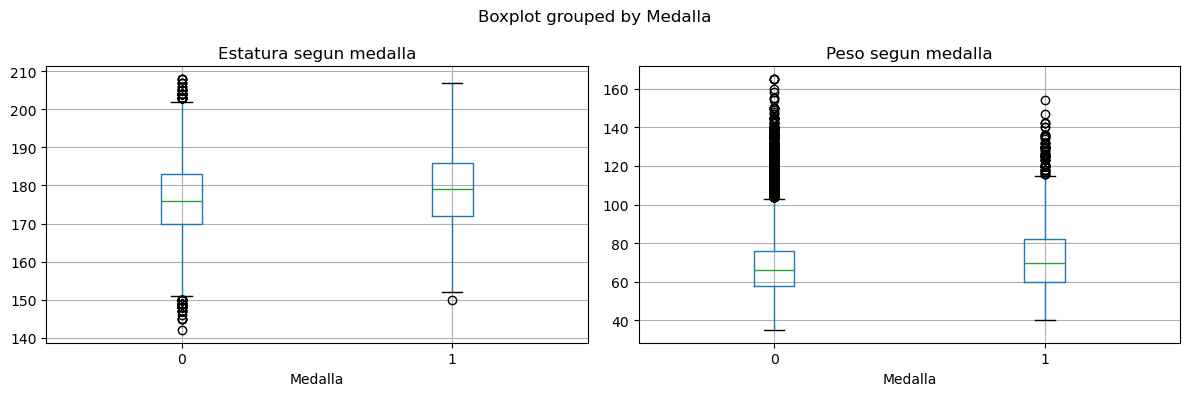

In [10]:
print('Tasa de medalla por categoria de prueba:')
print(atletismo.groupby('Categoria')['Medalla'].mean().sort_values(ascending=False).round(4))
print()
print('Correlacion Estatura-Peso:', atletismo['Height'].corr(atletismo['Weight']).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
atletismo.boxplot(column='Height', by='Medalla', ax=axes[0])
axes[0].set_title('Estatura segun medalla')
atletismo.boxplot(column='Weight', by='Medalla', ax=axes[1])
axes[1].set_title('Peso segun medalla')
plt.tight_layout()
plt.show()


**Conclusión del boxplot:** los medallistas tienden a ser un poco más altos y pesados que los no medallistas (mediana de estatura 178 cm vs. 176 cm, y de peso 69 kg vs. 66 kg), pero las dos distribuciones se solapan bastante y ambas tienen muchos valores atípicos en los extremos. Esto sugiere que Estatura y Peso sí aportan información, aunque por sí solas no separan claramente a un medallista de quien no lo es (coherente con el pseudo R² bajo que se ve más adelante).

## 3. Multicolinealidad (VIF)

Igual que en regresión múltiple, el logit asume que **no hay multicolinealidad severa** entre predictores (si no, los errores estándar se inflan y los coeficientes se vuelven inestables). Se revisa **antes** de ajustar el modelo, sobre las variables continuas + dummy de sexo (criterio: VIF > 5 o 10 es preocupante).

In [11]:
X_vif = atletismo[['Age', 'Height', 'Weight', 'Sexo_M']].astype(float)
X_vif = sm.add_constant(X_vif)

print('Variable       VIF')
for i, col in enumerate(X_vif.columns):
    if col == 'const':
        continue
    valor_vif = vif(X_vif.values, i)
    print(f'{col:12s}  {valor_vif:.3f}')

print()
print('Conclusion: todos los VIF estan muy por debajo de 5 -> no hay multicolinealidad problematica.')
print('(Height y Weight estan correlacionadas entre si (~0.75) pero no al punto de inflar varianzas.)')


Variable       VIF
Age           1.009
Height        2.727
Weight        2.325
Sexo_M        1.403

Conclusion: todos los VIF estan muy por debajo de 5 -> no hay multicolinealidad problematica.
(Height y Weight estan correlacionadas entre si (~0.75) pero no al punto de inflar varianzas.)


## 4. Ajuste del modelo logit completo

$$\ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 Edad + \beta_2 Estatura + \beta_3 Peso + \beta_4 Sexo_M + \sum \beta_j Categoria_j$$

donde $p = P(\text{Medalla}=1)$. Se usa `Combinadas` como categoría base de referencia (queda implícita, no se incluye como dummy: es la **trampa de la variable dummy**, igual que en regresión múltiple: $k$ categorías → $k-1$ dummies).

In [12]:
cat_dummies = pd.get_dummies(atletismo['Categoria'], prefix='Cat', drop_first=True).astype(float)
print('Categoria de referencia (no incluida como dummy):', 'Combinadas')
print('Dummies incluidas:', list(cat_dummies.columns))

X = pd.concat([atletismo[['Age', 'Height', 'Weight', 'Sexo_M']].astype(float), cat_dummies], axis=1)
X = sm.add_constant(X)
y = atletismo['Medalla'].astype(float)

modelo_completo = sm.Logit(y, X).fit(disp=0)
print(modelo_completo.summary())


Categoria de referencia (no incluida como dummy): Combinadas
Dummies incluidas: ['Cat_Lanzamientos', 'Cat_Marcha', 'Cat_Resistencia', 'Cat_Saltos', 'Cat_Velocidad']
                           Logit Regression Results                           
Dep. Variable:                Medalla   No. Observations:                21844
Model:                          Logit   Df Residuals:                    21834
Method:                           MLE   Df Model:                            9
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                 0.01866
Time:                        10:07:37   Log-Likelihood:                -5625.4
converged:                       True   LL-Null:                       -5732.3
Covariance Type:            nonrobust   LLR p-value:                 3.903e-41
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -8.6188      

## 5. Prueba global de significancia y eliminación hacia atrás

**Prueba global (razón de verosimilitud, LR test):** análoga a la prueba F global de OLS.

$H_0: \beta_1=\beta_2=\dots=\beta_k=0$ (ninguna variable aporta) vs. $H_1$: al menos una sí aporta.

In [13]:
alpha = 0.05
print(f"LLR p-value del modelo completo: {modelo_completo.llr_pvalue:.4e}")
if modelo_completo.llr_pvalue < alpha:
    print('Conclusion: se rechaza H0 -> el modelo en conjunto SI es significativo (al menos una variable aporta).')
else:
    print('Conclusion: no se rechaza H0 -> el modelo en conjunto no aporta explicacion.')


LLR p-value del modelo completo: 3.9033e-41
Conclusion: se rechaza H0 -> el modelo en conjunto SI es significativo (al menos una variable aporta).


**Eliminación hacia atrás dinámica:** igual patrón que en regresión múltiple: en cada vuelta se elimina la variable menos significativa, hasta que todas las que quedan tienen $p<\alpha$.

In [14]:
X_actual = X.copy()
ronda = 1
while True:
    modelo_actual = sm.Logit(y, X_actual).fit(disp=0)
    p_valores = modelo_actual.pvalues.drop('const')
    peor_variable = p_valores.idxmax()
    if p_valores[peor_variable] > alpha:
        print(f'Ronda {ronda}: se elimina {peor_variable} (p-valor={p_valores[peor_variable]:.4f})')
        X_actual = X_actual.drop(columns=[peor_variable])
        ronda += 1
    else:
        print('Todas las variables restantes son significativas -> se detiene la eliminacion.')
        break

modelo_final = modelo_actual
print()
print(modelo_final.summary())


Ronda 1: se elimina Cat_Resistencia (p-valor=0.7587)
Ronda 2: se elimina Cat_Saltos (p-valor=0.7454)
Ronda 3: se elimina Cat_Marcha (p-valor=0.7259)
Ronda 4: se elimina Age (p-valor=0.2560)
Todas las variables restantes son significativas -> se detiene la eliminacion.

                           Logit Regression Results                           
Dep. Variable:                Medalla   No. Observations:                21844
Model:                          Logit   Df Residuals:                    21838
Method:                           MLE   Df Model:                            5
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                 0.01852
Time:                        10:07:37   Log-Likelihood:                -5626.2
converged:                       True   LL-Null:                       -5732.3
Covariance Type:            nonrobust   LLR p-value:                 6.467e-44
                       coef    std err          z      P>|z|      [0.025      0.975]
-------------

**Hallazgo interesante:** `Edad` y las categorías Marcha/Resistencia/Saltos no son distinguibles de la categoría base (Combinadas) una vez controlado por estatura, peso y sexo. Lo que sí queda significativo: **Estatura, Peso, Sexo y ser lanzador o velocista** (vs. la base).

## 6. Interpretación: odds ratios

El coeficiente $\beta$ del logit está en escala *log-odds*. Para interpretarlo en términos de **cuántas veces cambian las probabilidades (odds)**, se exponencía: $OR = e^{\beta}$.

- $OR > 1$: la variable **aumenta** la probabilidad de medalla.
- $OR < 1$: la variable la **disminuye**.
- $OR = 1$: no tiene efecto.

In [15]:
odds_ratios = np.exp(modelo_final.params)
tabla_or = pd.DataFrame({'coef (log-odds)': modelo_final.params, 'Odds Ratio': odds_ratios})
print(tabla_or.round(4))
print()
print(f"Interpretacion Estatura: por cada cm adicional, las odds de medalla se multiplican por {odds_ratios['Height']:.4f}")
print(f"  (es decir, aumentan un {(odds_ratios['Height']-1)*100:.2f}% por cada cm, manteniendo lo demas constante).")
print(f"Interpretacion Sexo_M: ser hombre multiplica las odds de medalla por {odds_ratios['Sexo_M']:.4f}")
print(f"  (es decir, las reduce en un {(1-odds_ratios['Sexo_M'])*100:.2f}% respecto a ser mujer, manteniendo lo demas constante).")


                  coef (log-odds)  Odds Ratio
const                     -8.3151      0.0002
Height                     0.0314      1.0319
Weight                     0.0103      1.0104
Sexo_M                    -0.6894      0.5019
Cat_Lanzamientos          -0.2694      0.7638
Cat_Velocidad             -0.2113      0.8096

Interpretacion Estatura: por cada cm adicional, las odds de medalla se multiplican por 1.0319
  (es decir, aumentan un 3.19% por cada cm, manteniendo lo demas constante).
Interpretacion Sexo_M: ser hombre multiplica las odds de medalla por 0.5019
  (es decir, las reduce en un 49.81% respecto a ser mujer, manteniendo lo demas constante).


In [16]:
densidad_sexo = atletismo.groupby('Sex').agg(
    participaciones=('Medalla', 'count'),
    medallas=('Medalla', 'sum'),
    pct_medallistas=('Medalla', 'mean')
)
print(densidad_sexo)

     participaciones  medallas  pct_medallistas
Sex                                            
F               8201       662         0.080722
M              13643       942         0.069046


**¿Por qué el OR de Sexo_M es ~0.50?** No es que los hombres tengan menos capacidad atlética, es densidad de competencia. En esta misma muestra filtrada hay bastantes más participaciones masculinas que femeninas en atletismo, pero cada prueba (sea de hombres o de mujeres) siempre reparte las mismas 3 medallas. Con más hombres compitiendo por el mismo número de cupos, la probabilidad individual de cualquiera de ellos de ganar baja, y eso es justo lo que agarra el coeficiente de `Sexo_M`. Esto es consistente con el hallazgo de la sección 10.3: el cuerpo ideal no cambia, lo que cambia es cuánta gente compite por las medallas.

## 7. Bondad de ajuste

**Pseudo R² de McFadden:** no se interpreta como el R² de OLS (nunca llega cerca de 1 aunque el modelo sea bueno). Valores entre 0.02 y 0.4 ya se consideran razonables en McFadden (1974).

In [17]:
print(f'Pseudo R2 (McFadden): {modelo_final.prsquared:.4f}')
print(f'AIC: {modelo_final.aic:.2f}   BIC: {modelo_final.bic:.2f}')
print()
print('Conclusion: el pseudo R2 es bajo (~0.018), esperado: solo tenemos estatura/peso/sexo/categoria,')
print('sin ninguna medida de desempeño deportivo (marca, tiempo, records personales). El modelo SI es')
print('significativo (seccion 5), pero explica una fraccion pequena de por que alguien gana medalla.')


Pseudo R2 (McFadden): 0.0185
AIC: 11264.33   BIC: 11312.28

Conclusion: el pseudo R2 es bajo (~0.018), esperado: solo tenemos estatura/peso/sexo/categoria,
sin ninguna medida de desempeño deportivo (marca, tiempo, records personales). El modelo SI es
significativo (seccion 5), pero explica una fraccion pequena de por que alguien gana medalla.


**Prueba de Hosmer-Lemeshow:** evalúa si las probabilidades predichas calzan con las frecuencias observadas, agrupando en deciles de probabilidad.

$H_0$: el modelo ajusta bien (no hay diferencia entre lo observado y lo esperado por decil).

In [18]:
probs_final = modelo_final.predict(X_actual)
hl = pd.DataFrame({'y': y.values, 'p': probs_final.values})
hl['decil'] = pd.qcut(hl['p'], 10, duplicates='drop')

grupos = hl.groupby('decil', observed=True).agg(observados=('y', 'sum'), n=('y', 'count'), esperados=('p', 'sum'))
grupos['esperados_no'] = grupos['n'] - grupos['esperados']
grupos['observados_no'] = grupos['n'] - grupos['observados']

chi2_hl = ((grupos['observados'] - grupos['esperados'])**2 / grupos['esperados'] +
           (grupos['observados_no'] - grupos['esperados_no'])**2 / grupos['esperados_no']).sum()
gl_hl = len(grupos) - 2
p_valor_hl = 1 - st.chi2.cdf(chi2_hl, gl_hl)

print(f'Estadistico Hosmer-Lemeshow: {chi2_hl:.4f}, gl={gl_hl}, p-valor={p_valor_hl:.4f}')
if p_valor_hl < alpha:
    print('Conclusion: se rechaza H0 -> hay evidencia de que el ajuste no es perfecto en algunos tramos')
    print('de probabilidad (coherente con el pseudo R2 bajo: faltan variables relevantes como marca/tiempo).')
else:
    print('Conclusion: no se rechaza H0 -> no hay evidencia de falta de ajuste.')


Estadistico Hosmer-Lemeshow: 20.8937, gl=8, p-valor=0.0074
Conclusion: se rechaza H0 -> hay evidencia de que el ajuste no es perfecto en algunos tramos
de probabilidad (coherente con el pseudo R2 bajo: faltan variables relevantes como marca/tiempo).


## 8. Supuesto de linealidad en el logit (prueba de Box-Tidwell)

El logit asume que el **log-odds** es lineal en las variables continuas (no la probabilidad misma, que sí es una S). Se prueba agregando el término $X\ln(X)$: si sale significativo, la relación no es lineal en el logit y se necesitaría transformar la variable.

In [19]:
X_bt = X_actual.copy()
X_bt['Height_lnHeight'] = atletismo['Height'].values * np.log(atletismo['Height'].values)
X_bt['Weight_lnWeight'] = atletismo['Weight'].values * np.log(atletismo['Weight'].values)

modelo_bt = sm.Logit(y, X_bt).fit(disp=0)
p_height_bt = modelo_bt.pvalues['Height_lnHeight']
p_weight_bt = modelo_bt.pvalues['Weight_lnWeight']
print(f'p-valor termino Height*ln(Height): {p_height_bt:.4f}')
print(f'p-valor termino Weight*ln(Weight): {p_weight_bt:.4f}')

if p_height_bt > alpha and p_weight_bt > alpha:
    print('Conclusion: ambos terminos NO son significativos -> no se rechaza linealidad en el logit,')
    print('se cumple el supuesto para Estatura y Peso.')
else:
    print('Conclusion: al menos un termino es significativo -> se viola linealidad en el logit, considerar transformar.')


p-valor termino Height*ln(Height): 0.7955
p-valor termino Weight*ln(Weight): 0.5866
Conclusion: ambos terminos NO son significativos -> no se rechaza linealidad en el logit,
se cumple el supuesto para Estatura y Peso.


## 9. Evaluación predictiva (train/test)

Se divide 75%/25% y se evalúa fuera de muestra. **Ojo con el accuracy:** como solo ~7% de la muestra son medallistas, un modelo que *nunca* prediga medalla ya tendría ~93% de accuracy sin servir para nada ("paradoja del accuracy" en clases desbalanceadas), por eso también se mira precision, recall, F1 y la curva ROC.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X_actual, y, test_size=0.25, random_state=42, stratify=y
)
modelo_train = sm.Logit(y_train, X_train).fit(disp=0)
probs_test = modelo_train.predict(X_test)

pred_05 = (probs_test >= 0.5).astype(int)
print('--- Umbral ingenuo de 0.5 ---')
print(f"Accuracy:  {accuracy_score(y_test, pred_05):.4f}")
print(f"Recall:    {recall_score(y_test, pred_05):.4f}")
print('Conclusion: accuracy altisimo pero el modelo NUNCA predice medalla (recall=0) -> inutil con este umbral.')


--- Umbral ingenuo de 0.5 ---
Accuracy:  0.9266
Recall:    0.0000
Conclusion: accuracy altisimo pero el modelo NUNCA predice medalla (recall=0) -> inutil con este umbral.


AUC: 0.5849
Umbral optimo (Youden J): 0.0759


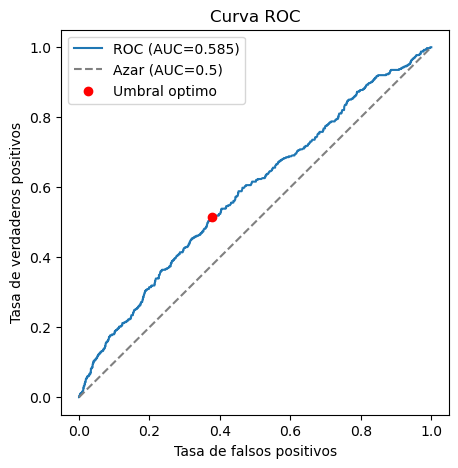

Conclusion: AUC=0.585 > 0.5 -> el modelo discrimina mejor que el azar, aunque de forma modesta
(AUC cercano a 0.6 se considera discriminacion debil-aceptable, no fuerte).


In [21]:
# buscamos el umbral optimo con el indice de Youden (maximiza TPR - FPR) sobre la curva ROC
fpr, tpr, umbrales = roc_curve(y_test, probs_test)
indice_j = tpr - fpr
pos_optima = np.argmax(indice_j)
umbral_optimo = umbrales[pos_optima]

auc = roc_auc_score(y_test, probs_test)
print(f'AUC: {auc:.4f}')
print(f'Umbral optimo (Youden J): {umbral_optimo:.4f}')

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f'ROC (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Azar (AUC=0.5)')
plt.scatter(fpr[pos_optima], tpr[pos_optima], color='red', zorder=5, label='Umbral optimo')
plt.xlabel('Tasa de falsos positivos'); plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC'); plt.legend()
plt.show()

if auc > 0.5:
    print(f'Conclusion: AUC={auc:.3f} > 0.5 -> el modelo discrimina mejor que el azar, aunque de forma modesta')
    print('(AUC cercano a 0.6 se considera discriminacion debil-aceptable, no fuerte).')
else:
    print('Conclusion: AUC <= 0.5 -> el modelo no discrimina mejor que el azar.')


In [22]:
pred_opt = (probs_test >= umbral_optimo).astype(int)
matriz = confusion_matrix(y_test, pred_opt)
print('--- Con el umbral optimo ---')
print('Matriz de confusion [[VN, FP],[FN, VP]]:')
print(matriz)
print(f"Accuracy:  {accuracy_score(y_test, pred_opt):.4f}")
print(f"Precision: {precision_score(y_test, pred_opt):.4f}")
print(f"Recall:    {recall_score(y_test, pred_opt):.4f}")
print(f"F1:        {f1_score(y_test, pred_opt):.4f}")
print()
print('Conclusion: bajando el umbral se sacrifica accuracy global pero se recupera la capacidad de detectar')
print('medallistas (recall ~0.51) -> la eleccion del umbral depende de que error nos importa mas evitar.')


--- Con el umbral optimo ---
Matriz de confusion [[VN, FP],[FN, VP]]:
[[3155 1905]
 [ 195  206]]
Accuracy:  0.6155
Precision: 0.0976
Recall:    0.5137
F1:        0.1640

Conclusion: bajando el umbral se sacrifica accuracy global pero se recupera la capacidad de detectar
medallistas (recall ~0.51) -> la eleccion del umbral depende de que error nos importa mas evitar.


> **Cómo te lo pueden preguntar:** *"El modelo tiene 92.6% de accuracy con umbral 0.5, ¿es un buen modelo?"*
>
> **Respuesta modelo:** no necesariamente: hay que revisar la matriz de confusión. Con clases desbalanceadas (solo ~7% positivos), un modelo que prediga "no medalla" siempre ya logra ~93% de accuracy sin ser útil (recall=0%). Hay que mirar también precision, recall, F1 y AUC, y elegir el umbral según qué tipo de error (falso positivo vs. falso negativo) es más costoso para el caso de uso.

### 9.1 ¿Ayuda balancear las clases?

Se prueba **oversampling** (duplicar con reemplazo observaciones de la clase minoritaria) sobre `X_train`/`y_train` únicamente, dejando `X_test`/`y_test` intactos (balancear el test sería trampa: dejaría de reflejar la proporción real de medallistas). Se compara el modelo entrenado así, con umbral ingenuo 0.5, contra el modelo original con el umbral óptimo de Youden ya calculado arriba.

In [23]:
from sklearn.utils import resample

train = X_train.copy()
train['y'] = y_train.values
mayoria = train[train['y'] == 0]
minoria = train[train['y'] == 1]
minoria_oversample = resample(minoria, replace=True, n_samples=len(mayoria), random_state=42)
train_bal = pd.concat([mayoria, minoria_oversample])

y_train_bal = train_bal['y']
X_train_bal = train_bal.drop(columns=['y'])
print('Train balanceado:', X_train_bal.shape[0], 'filas, proporcion de medallistas:', y_train_bal.mean())

modelo_bal = sm.Logit(y_train_bal, X_train_bal).fit(disp=0)
probs_test_bal = modelo_bal.predict(X_test)
pred_bal = (probs_test_bal >= 0.5).astype(int)
auc_bal = roc_auc_score(y_test, probs_test_bal)

matriz_bal = confusion_matrix(y_test, pred_bal)
print()
print('--- Modelo balanceado (oversampling), umbral 0.5, evaluado sobre el MISMO test set ---')
print('Matriz de confusion [[VN, FP],[FN, VP]]:')
print(matriz_bal)
print(f"Accuracy:  {accuracy_score(y_test, pred_bal):.4f}")
print(f"Precision: {precision_score(y_test, pred_bal):.4f}")
print(f"Recall:    {recall_score(y_test, pred_bal):.4f}")
print(f"F1:        {f1_score(y_test, pred_bal):.4f}")
print(f"AUC:       {auc_bal:.4f}")

print()
comparacion = pd.DataFrame({
    'Original (umbral optimo Youden)': [accuracy_score(y_test, pred_opt), precision_score(y_test, pred_opt),
                                         recall_score(y_test, pred_opt), f1_score(y_test, pred_opt), auc],
    'Balanceado (oversampling, umbral 0.5)': [accuracy_score(y_test, pred_bal), precision_score(y_test, pred_bal),
                                               recall_score(y_test, pred_bal), f1_score(y_test, pred_bal), auc_bal],
}, index=['Accuracy', 'Precision', 'Recall', 'F1', 'AUC'])
print(comparacion.round(4))

Train balanceado: 30360 filas, proporcion de medallistas: 0.5



--- Modelo balanceado (oversampling), umbral 0.5, evaluado sobre el MISMO test set ---
Matriz de confusion [[VN, FP],[FN, VP]]:
[[3001 2059]
 [ 192  209]]


Accuracy:  0.5878
Precision: 0.0922
Recall:    0.5212
F1:        0.1566
AUC:       0.5843

           Original (umbral optimo Youden)  \
Accuracy                            0.6155   
Precision                           0.0976   
Recall                              0.5137   
F1                                  0.1640   
AUC                                 0.5849   

           Balanceado (oversampling, umbral 0.5)  
Accuracy                                  0.5878  
Precision                                 0.0922  
Recall                                    0.5212  
F1                                        0.1566  
AUC                                       0.5843  


**Conclusión:** el modelo balanceado (oversampling + umbral 0.5) y el modelo original (sin balancear + umbral óptimo de Youden) llegan a métricas prácticamente iguales (AUC ≈ 0.584 en ambos, recall ~0.51-0.52, accuracy ~0.59-0.62). Esto no es casualidad: duplicar filas de la clase minoritaria no le agrega información nueva al modelo, solo corre el intercepto para que el umbral ingenuo de 0.5 se comporte como el umbral que ya habíamos encontrado moviendo el punto de corte. En otras palabras, para este modelo balancear las clases es equivalente a elegir un buen umbral, no es una mejora adicional. La forma de subir el AUC de verdad sería agregar variables con más poder predictivo (marca, tiempo, ranking previo), no técnicas de remuestreo.

## 10. Predicción para un atleta hipotético

Con el modelo completo (toda la muestra), se calcula la probabilidad estimada de medalla para dos perfiles distintos.

In [24]:
modelo_reporte = sm.Logit(y, X_actual).fit(disp=0)

perfil_1 = pd.DataFrame({col: [0] for col in X_actual.columns})
perfil_1['const'] = 1
perfil_1['Height'] = 190
perfil_1['Weight'] = 85
perfil_1['Sexo_M'] = 1
if 'Cat_Lanzamientos' in perfil_1.columns:
    perfil_1['Cat_Lanzamientos'] = 1

perfil_2 = pd.DataFrame({col: [0] for col in X_actual.columns})
perfil_2['const'] = 1
perfil_2['Height'] = 178
perfil_2['Weight'] = 62
perfil_2['Sexo_M'] = 0
if 'Cat_Velocidad' in perfil_2.columns:
    perfil_2['Cat_Velocidad'] = 1

p1 = modelo_reporte.predict(perfil_1).iloc[0]
p2 = modelo_reporte.predict(perfil_2).iloc[0]
print(f'Perfil 1 (hombre, 190cm, 85kg, lanzador):   P(medalla) = {p1:.4f}')
print(f'Perfil 2 (mujer, 178cm, 62kg, velocista):    P(medalla) = {p2:.4f}')


Perfil 1 (hombre, 190cm, 85kg, lanzador):   P(medalla) = 0.0814
Perfil 2 (mujer, 178cm, 62kg, velocista):    P(medalla) = 0.0919


### 10.1 Predicción con atletas famosos reales

Se usan estatura y peso públicamente conocidos de atletas reales (aproximados) para ver qué dice el modelo sobre cada uno, dado su sexo y categoría de prueba.

In [25]:
famosos = pd.DataFrame([
    {'Nombre': 'Usain Bolt (velocista)',           'Height': 195, 'Weight': 94,  'Sexo_M': 1, 'Cat_Lanzamientos': 0, 'Cat_Velocidad': 1},
    {'Nombre': 'Allyson Felix (velocista)',        'Height': 165, 'Weight': 57,  'Sexo_M': 0, 'Cat_Lanzamientos': 0, 'Cat_Velocidad': 1},
    {'Nombre': 'Valerie Adams (lanzadora de bala)','Height': 193, 'Weight': 120, 'Sexo_M': 0, 'Cat_Lanzamientos': 1, 'Cat_Velocidad': 0},
    {'Nombre': 'Eliud Kipchoge (maratonista)',     'Height': 167, 'Weight': 52,  'Sexo_M': 1, 'Cat_Lanzamientos': 0, 'Cat_Velocidad': 0},
    {'Nombre': 'Yelena Isinbayeva (garrocha)',     'Height': 174, 'Weight': 64,  'Sexo_M': 0, 'Cat_Lanzamientos': 0, 'Cat_Velocidad': 0},
])
famosos['const'] = 1.0
Xf = famosos[X_actual.columns].astype(float)
famosos['P_medalla'] = modelo_reporte.predict(Xf)

print(famosos[['Nombre', 'P_medalla']].sort_values('P_medalla', ascending=False).to_string(index=False))
print()
print('Nota: Kipchoge y la garrochista caen en "Resistencia"/"Saltos", categorias que NO resultaron')
print('significativamente distintas de la base (Combinadas) en la eliminacion hacia atras -> su P(medalla)')
print('depende solo de estatura/peso/sexo, no de un efecto de categoria adicional.')


                           Nombre  P_medalla
Valerie Adams (lanzadora de bala)   0.217876
           Usain Bolt (velocista)   0.107619
     Yelena Isinbayeva (garrocha)   0.101120
        Allyson Felix (velocista)   0.060011
     Eliud Kipchoge (maratonista)   0.038483

Nota: Kipchoge y la garrochista caen en "Resistencia"/"Saltos", categorias que NO resultaron
significativamente distintas de la base (Combinadas) en la eliminacion hacia atras -> su P(medalla)
depende solo de estatura/peso/sexo, no de un efecto de categoria adicional.


### 10.2 Mapa de calor: probabilidad de medalla según estatura y peso

Se evalúa el modelo final sobre una malla de combinaciones de Estatura×Peso, separando por sexo y por las dos categorías que resultaron significativas (Velocidad y Lanzamientos), para ver visualmente cómo se mueve el "punto dulce" físico en cada caso.

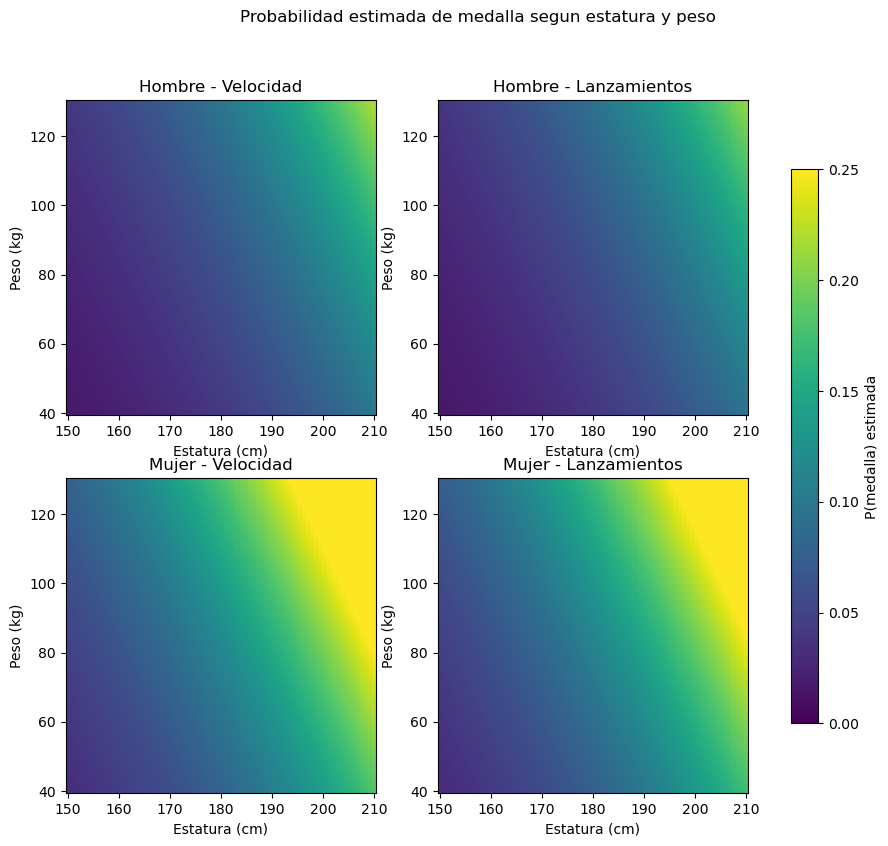

In [26]:
alturas = np.linspace(150, 210, 80)
pesos = np.linspace(40, 130, 80)
Malturas, Mpesos = np.meshgrid(alturas, pesos)

perfiles = [
    ('Hombre - Velocidad', 1, 'Cat_Velocidad'),
    ('Hombre - Lanzamientos', 1, 'Cat_Lanzamientos'),
    ('Mujer - Velocidad', 0, 'Cat_Velocidad'),
    ('Mujer - Lanzamientos', 0, 'Cat_Lanzamientos'),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (titulo, sexo_m, cat_col) in zip(axes.flat, perfiles):
    grid = pd.DataFrame({
        'const': 1.0,
        'Height': Malturas.ravel(),
        'Weight': Mpesos.ravel(),
        'Sexo_M': sexo_m,
        'Cat_Lanzamientos': 1.0 if cat_col == 'Cat_Lanzamientos' else 0.0,
        'Cat_Velocidad': 1.0 if cat_col == 'Cat_Velocidad' else 0.0,
    })[X_actual.columns]
    probs_grid = modelo_reporte.predict(grid).values.reshape(Malturas.shape)
    malla = ax.pcolormesh(Malturas, Mpesos, probs_grid, cmap='viridis', vmin=0, vmax=0.25, shading='auto')
    ax.set_title(titulo)
    ax.set_xlabel('Estatura (cm)')
    ax.set_ylabel('Peso (kg)')

fig.colorbar(malla, ax=axes, shrink=0.8, label='P(medalla) estimada')
fig.suptitle('Probabilidad estimada de medalla segun estatura y peso')
plt.show()


### 10.3 ¿Ha cambiado el "cuerpo ideal" con el tiempo?

Se agregan interacciones Estatura×Año y Peso×Año (centrando las variables para que los coeficientes sean interpretables) para ver si el perfil físico ganador de 1960 es distinto al de 2016.

In [27]:
atletismo['Year_c'] = atletismo['Year'] - atletismo['Year'].mean()
atletismo['Height_c'] = atletismo['Height'] - atletismo['Height'].mean()
atletismo['Weight_c'] = atletismo['Weight'] - atletismo['Weight'].mean()

X_tiempo = pd.DataFrame({
    'Height_c': atletismo['Height_c'], 'Weight_c': atletismo['Weight_c'], 'Sexo_M': atletismo['Sexo_M'],
    'Cat_Lanzamientos': cat_dummies['Cat_Lanzamientos'], 'Cat_Velocidad': cat_dummies['Cat_Velocidad'],
    'Year_c': atletismo['Year_c']
})
X_tiempo['Height_x_Year'] = X_tiempo['Height_c'] * X_tiempo['Year_c']
X_tiempo['Weight_x_Year'] = X_tiempo['Weight_c'] * X_tiempo['Year_c']
X_tiempo = sm.add_constant(X_tiempo)

modelo_tiempo = sm.Logit(y, X_tiempo).fit(disp=0)
print(modelo_tiempo.summary())

print()
p_h_year = modelo_tiempo.pvalues['Height_x_Year']
p_w_year = modelo_tiempo.pvalues['Weight_x_Year']
p_year = modelo_tiempo.pvalues['Year_c']
print(f"p-valor Estatura x Año: {p_h_year:.4f}  ->  {'NO' if p_h_year > alpha else 'SI'} significativo")
print(f"p-valor Peso x Año:     {p_w_year:.4f}  ->  {'NO' if p_w_year > alpha else 'SI'} significativo")
print(f"p-valor Año (solo):     {p_year:.4f}  ->  {'NO' if p_year > alpha else 'SI'} significativo")


                           Logit Regression Results                           
Dep. Variable:                Medalla   No. Observations:                21844
Model:                          Logit   Df Residuals:                    21835
Method:                           MLE   Df Model:                            8
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                 0.02514
Time:                        10:07:38   Log-Likelihood:                -5588.2
converged:                       True   LL-Null:                       -5732.3
Covariance Type:            nonrobust   LLR p-value:                 1.342e-57
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.9812      0.062    -31.900      0.000      -2.103      -1.859
Height_c             0.0337      0.005      7.226      0.000       0.025       0.043
Weight_c             0.0117 

**Interpretación del hallazgo anterior:** la interacción Estatura×Año y Peso×Año no es significativa, el efecto del cuerpo sobre la probabilidad de medalla **no ha cambiado** en 56 años de Juegos Olímpicos (1960-2016). Lo que sí cambió, y de forma significativa, es `Year_c` por sí solo: cada año que pasa, la probabilidad de medalla cae, manteniendo el cuerpo fijo.  
   
Esto es interesantre en mi conclusión es porque cada vez participan más países y más atletas por el mismo número de medallas (siempre 3 por prueba), así que el "pastel" de medallas se reparte entre más gente. El cuerpo ideal no cambió; lo que cambió es cuánta gente compite por él, hay una proporción mucho menor de medalas por cantidad de persona sque compiten 

## 11. Conclusiones generales

1. **El modelo es globalmente significativo** (LR test, p≈0) pero explica una fracción modesta de la variabilidad (pseudo R² McFadden ≈ 0.018-0.019): esperado, ya que solo se usan rasgos físicos, sin ninguna medida directa de desempeño deportivo.
2. Tras la eliminación hacia atrás, el modelo final retiene: **Estatura, Peso, Sexo y Categoría de prueba** (Lanzamientos y Velocidad se diferencian de la base; Edad y las demás categorías no aportan de forma significativa una vez controladas las demás variables).
3. **No hay violaciones graves de supuestos**: la multicolinealidad es baja (VIF<5), y se cumple la linealidad en el logit para Estatura y Peso (Box-Tidwell). La prueba de Hosmer-Lemeshow sugiere que el ajuste no es perfecto en algunos tramos, coherente con el pseudo R² bajo.
4. El poder predictivo fuera de muestra es **discreto pero mejor que el azar** (AUC≈0.58): suficiente para decir que el cuerpo del atleta y la prueba que corre sí importan, pero lejos de ser suficiente para predecir medallas con confianza; el desempeño real en la prueba (marca, tiempo, ranking previo) sería un predictor mucho más fuerte y sería el siguiente paso natural del análisis.